GPU: Tesla T4
Enter your image prompt: A tiny baby otter floating on a shimmering crystal river, surrounded by water lilies and floating lanterns, magical night
Loading SDXL model...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Generating image for prompt: 'A tiny baby otter floating on a shimmering crystal river, surrounded by water lilies and floating lanterns, magical night' ...


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Done! Saved to outputs/image_1794988230_529905011.png | Seed: 529905011


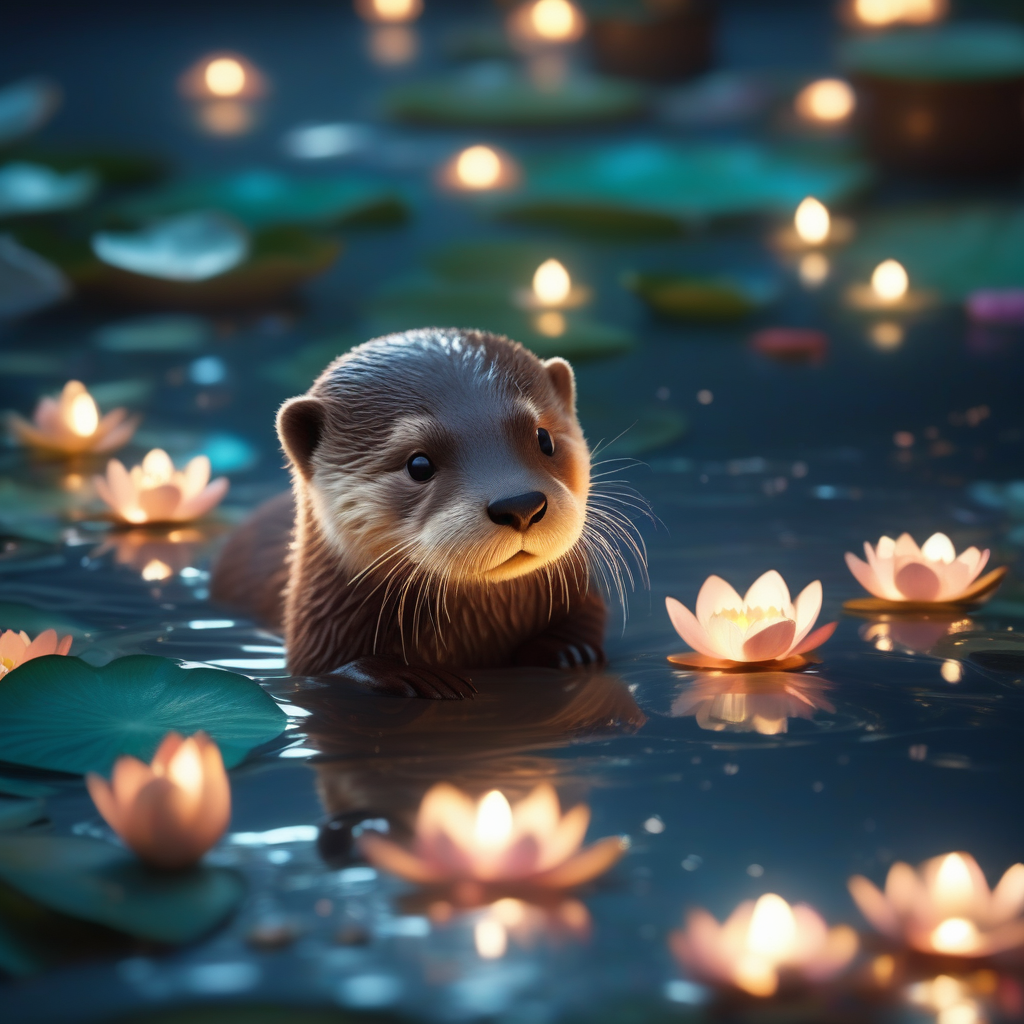

In [2]:
# ============================================================
# Prompt -> HD Image (SDXL) [Interactive Input Version]
# ============================================================

!pip -q uninstall -y torchao 2>/dev/null
!pip -q install -U diffusers transformers accelerate safetensors huggingface_hub

import sys
for name in list(sys.modules):
    if name.split(".")[0] in ("diffusers", "torchao"):
        del sys.modules[name]

import gc, os, random, time, warnings
warnings.filterwarnings("ignore")

import torch
from PIL import Image
from diffusers import AutoencoderKL, StableDiffusionXLPipeline
from IPython.display import display

if not torch.cuda.is_available():
    raise RuntimeError("No GPU found. Runtime > Change runtime type > T4 GPU, then run again.")
print("GPU:", torch.cuda.get_device_name(0))

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

WIDTH, HEIGHT = 1024, 1024    # Standard SDXL native resolution
QUALITY_SUFFIX = ", highly detailed, sharp focus, professional photography, cinematic lighting, 8k, high quality"
NEGATIVE = ("blurry, out of focus, low quality, low resolution, jpeg artifacts, deformed, "
            "bad anatomy, extra limbs, text, watermark, logo, oversaturated, noisy")

def free_memory():
    gc.collect()
    torch.cuda.empty_cache()

def generate_image(prompt, steps=30, guidance=7.0, seed=-1):
    if not prompt or not prompt.strip():
        raise ValueError("Please enter a valid prompt.")

    print("Loading SDXL model...")
    vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
    pipe = StableDiffusionXLPipeline.from_pretrained(
        "stabilityai/stable-diffusion-xl-base-1.0",
        vae=vae,
        torch_dtype=torch.float16,
        variant="fp16",
        use_safetensors=True,
    )
    pipe.enable_model_cpu_offload()

    if seed < 0:
        seed = random.randint(0, 2**31 - 1)

    print(f"Generating image for prompt: '{prompt}' ...")
    image = pipe(
        prompt=prompt + QUALITY_SUFFIX,
        negative_prompt=NEGATIVE,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance),
        width=WIDTH,
        height=HEIGHT,
        generator=torch.Generator("cuda").manual_seed(seed),
    ).images[0]

    stamp = int(time.time())
    image_path = os.path.join(OUTPUT_DIR, f"image_{stamp}_{seed}.png")
    image.save(image_path)

    print(f"✅ Done! Saved to {image_path} | Seed: {seed}")

    # Clean up memory
    del pipe, vae
    free_memory()

    return image, image_path

# ============================================================
# Run Image Generation Here (Interactive Prompt Input)
# ============================================================
my_prompt = input("Enter your image prompt: ")

if my_prompt.strip():
    img, path = generate_image(
        prompt=my_prompt,
        steps=30,       # Number of steps (20 - 50)
        guidance=7.0,   # Guidance scale (4.0 - 10.0)
        seed=-1         # -1 for random seed, or put a specific number
    )

    # Display the image right inside Colab
    display(img)
else:
    print("❌ Prompt cannot be empty. Please run the cell again and enter a prompt.")